In [2]:
import scanpy as sc
import scanpy.external as sce
import scirpy as ir
import mudata as md
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import random
random.seed(42)

import warnings
warnings.filterwarnings("ignore")

sc.settings.max_memory=10
sc.settings.n_jobs=7

import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.set_figure_params(scanpy=True, dpi=80, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14,
                     figsize=(5,5),
                     color_map=None, format='pdf',
                     facecolor=None, transparent=False, ipython_format='png2x')

## Data preprocessing

### demultiplex

In [3]:
hashtag_dict = {
    'HTO01':'HT1',
    'HTO02':'HT2',
    'HTO03':'HT3',  
    'HTO04':'HT4',
    'HTO05':'HT5',    
    'HTO06':'inflamed_skin',
    'HTO07':'NONinflamed_skin',
    'HTO08':'CLA_neg',
    'HTO09':'CLA_pos'
}

In [4]:
ad16 = sc.read_10x_h5('Laura_SAD_scRNA/CellRanger_out/SAD16/sample_filtered_feature_bc_matrix.h5', gex_only=False)
ad16.var_names_make_unique()   

hto_mask = ad16.var["feature_types"] == "Antibody Capture"
ad16_gex = ad16[:, ~hto_mask].copy()
ad16_hto = ad16[:, hto_mask].copy()
hto_df = pd.DataFrame(
        ad16_hto.X.toarray(),
        index=ad16_hto.obs_names,
        columns=ad16_hto.var['gene_ids'].map(hashtag_dict)
    )
ad16_gex.obs = ad16_gex.obs.join(hto_df)
hashtag_cols = list(hto_df.columns)  
sce.pp.hashsolo(ad16_gex, hashtag_cols)

ad16_gex.obs = ad16_gex.obs[['Classification']]
# manual hashtag assignment to override hashsolo's doublets
ad16_gex.obs['hash'] = hto_df.idxmax(axis=1)
ad16_gex.obs['ambiguous'] = (hto_df.T > 0.2*hto_df.sum(axis=1)).sum()>1

ad16_tcr = ir.io.read_10x_vdj('Laura_SAD_scRNA/CellRanger_out/SAD16/vdj_t/filtered_contig_annotations.csv')
ad16 = md.MuData({"gex": ad16_gex, "airr": ad16_tcr})

Please cite HashSolo paper:
https://www.cell.com/cell-systems/fulltext/S2405-4712(20)30195-2


In [5]:
ad17 = sc.read_10x_mtx('Laura_SAD_scRNA/CellRanger_out/SAD17/sample_filtered_feature_bc_matrix', gex_only=False)
ad17.var_names_make_unique()   

hto_mask = ad17.var["feature_types"] == "Antibody Capture"
ad17_gex = ad17[:, ~hto_mask].copy()
ad17_hto = ad17[:, hto_mask].copy()
hto_df = pd.DataFrame(
        ad17_hto.X.toarray(),
        index=ad17_hto.obs_names,
        columns=ad17_hto.var['gene_ids'].map(hashtag_dict)
    )
ad17_gex.obs = ad17_gex.obs.join(hto_df)
hashtag_cols = list(hto_df.columns)  
sce.pp.hashsolo(ad17_gex, hashtag_cols)
ad17_gex.obs = ad17_gex.obs[['Classification']]

# manual hashtag assignment to override hashsolo's doublets
ad17_gex.obs['hash'] = hto_df.idxmax(axis=1)
ad17_gex.obs['ambiguous'] = (hto_df.T > 0.2*hto_df.sum(axis=1)).sum()>1

ad17_tcr = ir.io.read_10x_vdj('Laura_SAD_scRNA/CellRanger_out/SAD17/vdj_t/filtered_contig_annotations.csv')
ad17 = md.MuData({"gex": ad17_gex, "airr": ad17_tcr})

Please cite HashSolo paper:
https://www.cell.com/cell-systems/fulltext/S2405-4712(20)30195-2


In [63]:
ad = md.concat([ad16,ad17],label="batch", index_unique='batch')

In [64]:
ad_gex = ad['gex']

### QC

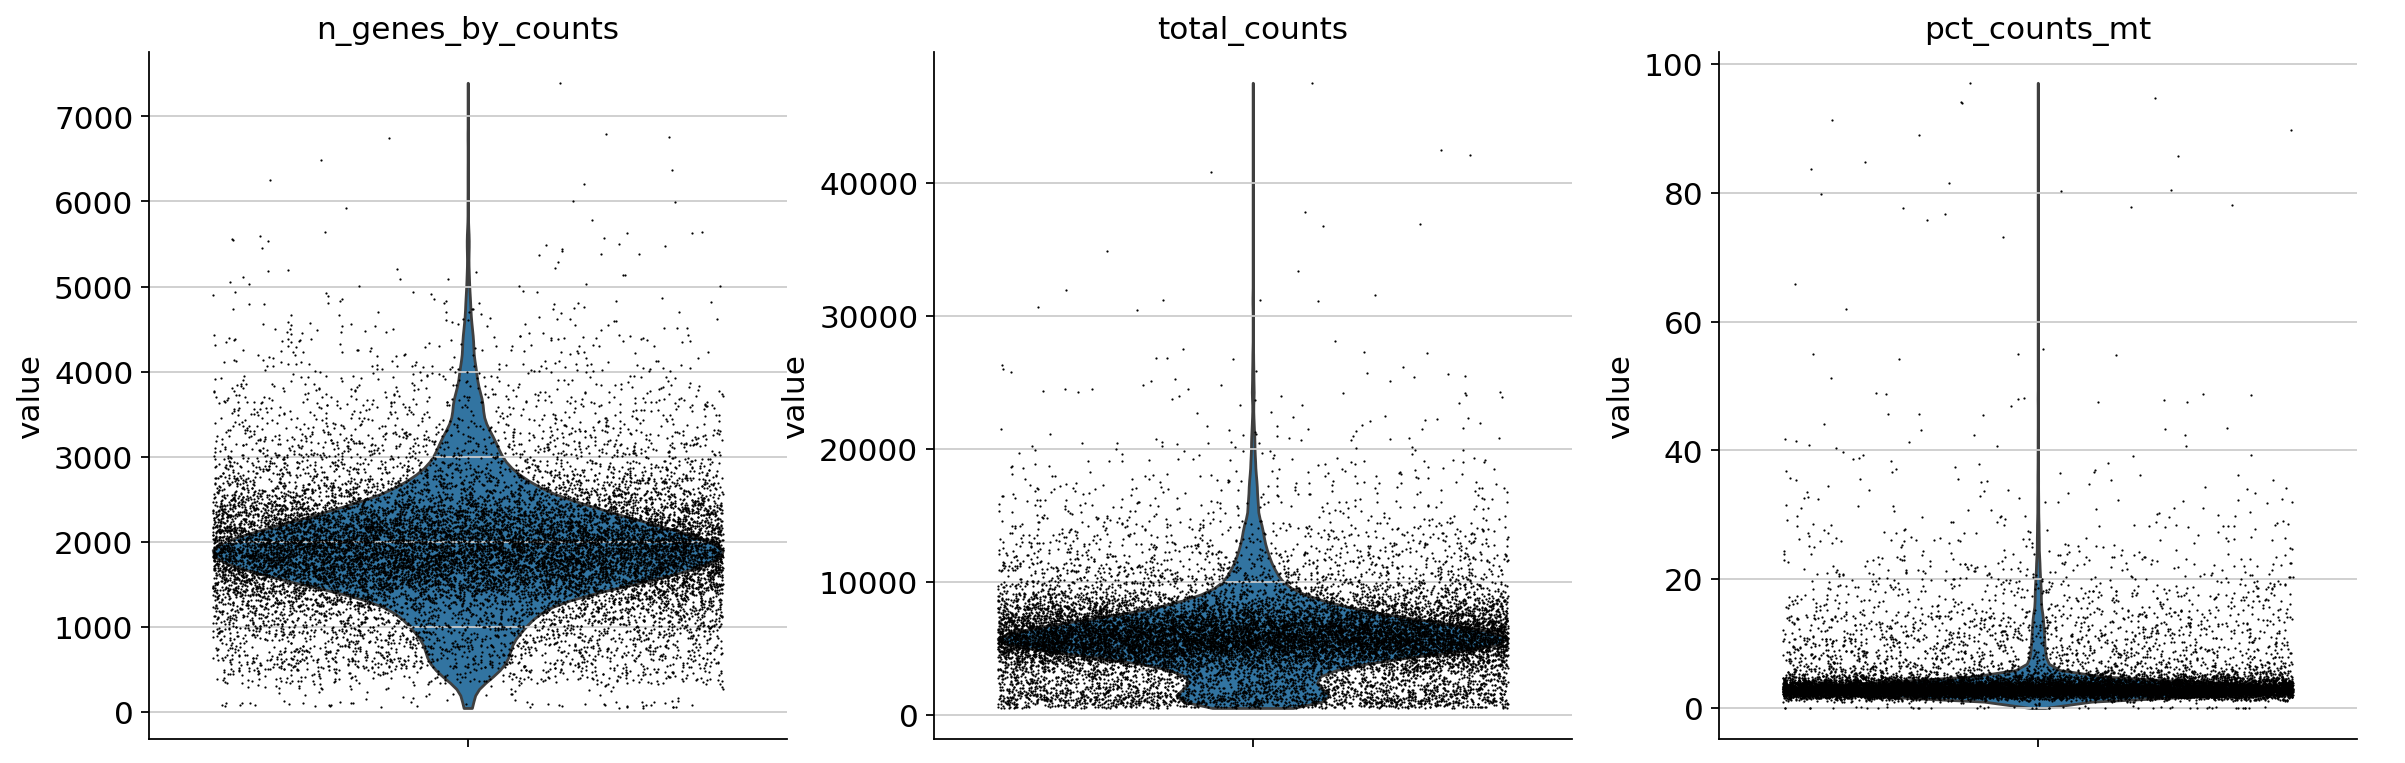

Original cell n: 16046
MT filtering: 13782 cells left
Counts filtering: 13651 cells left


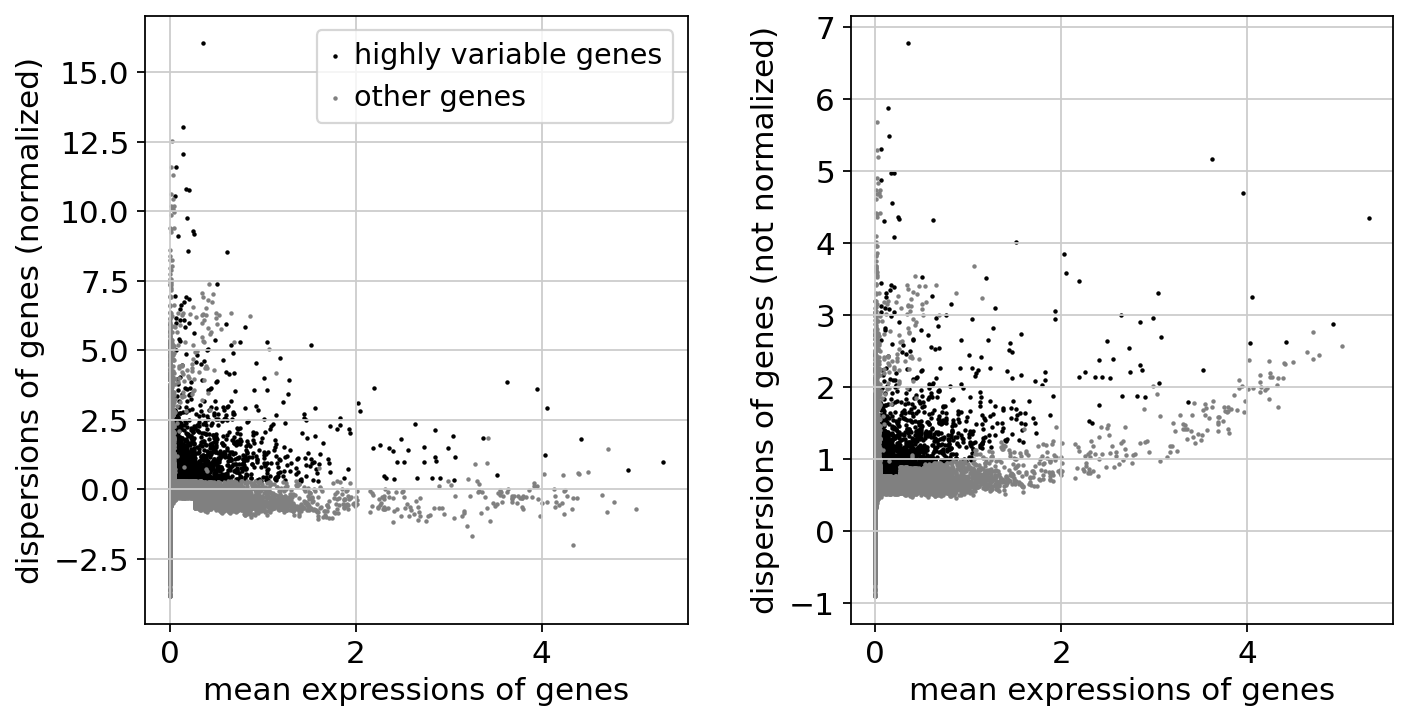

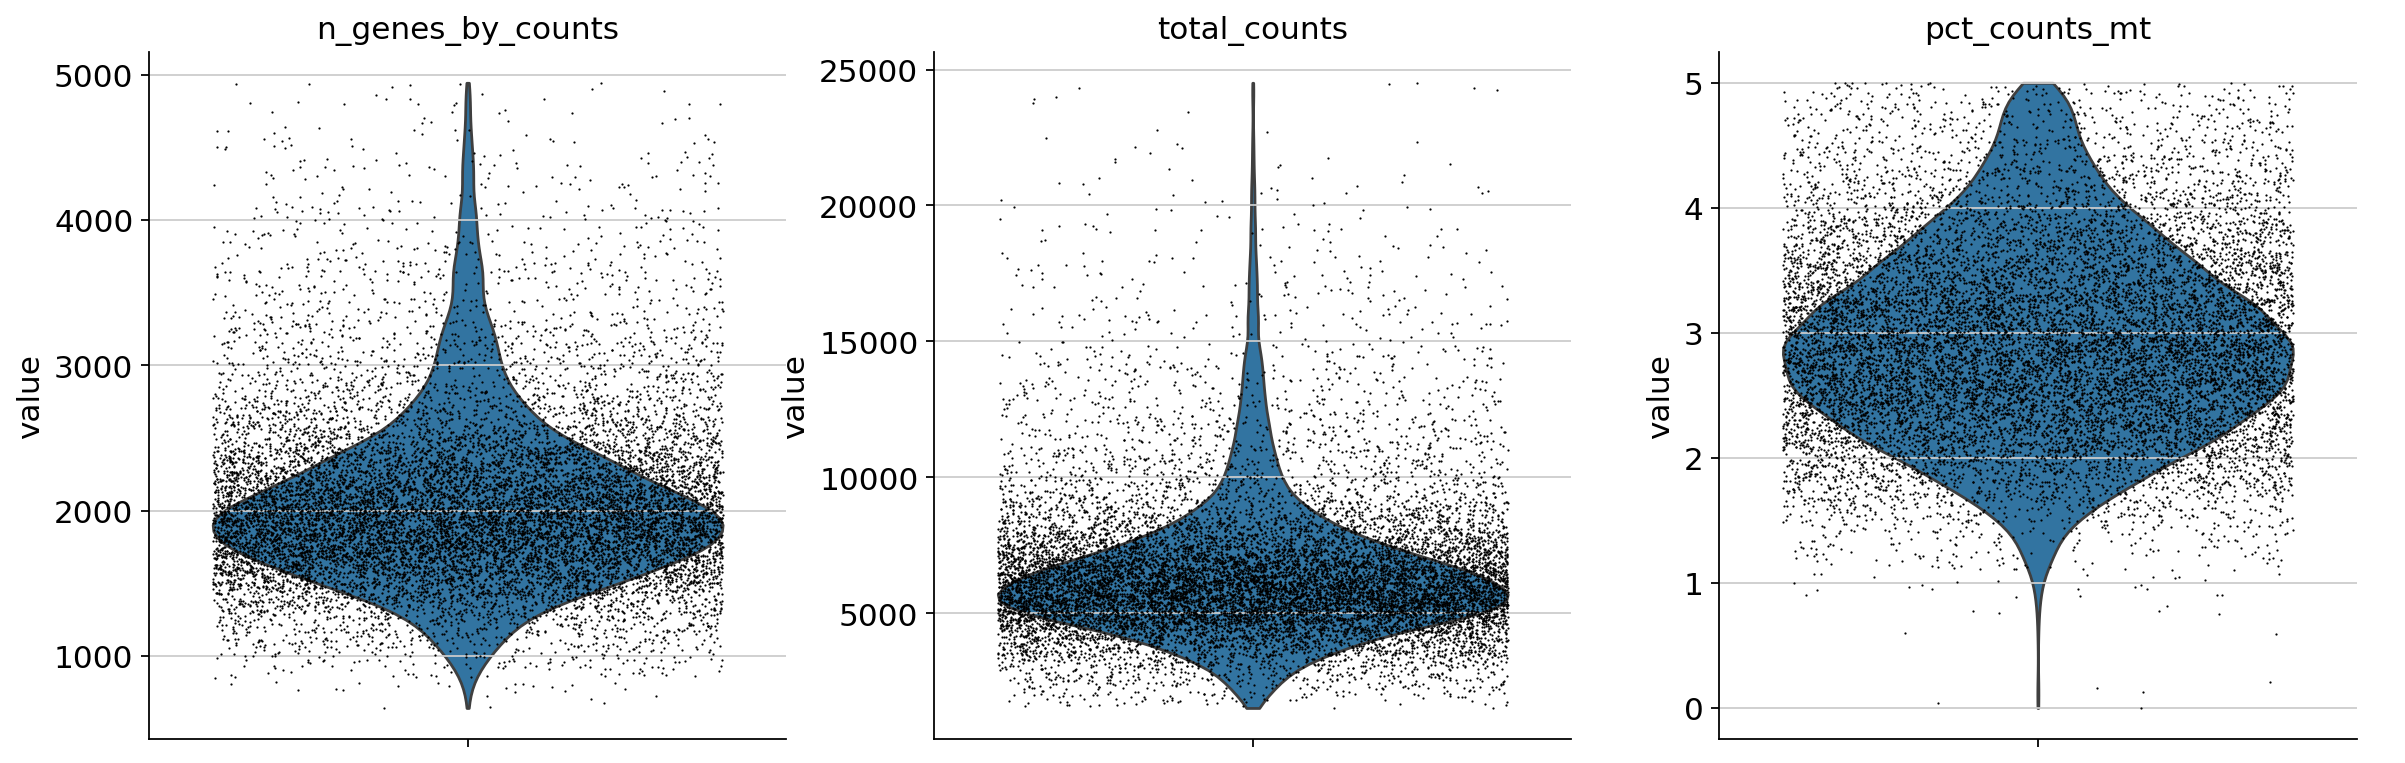

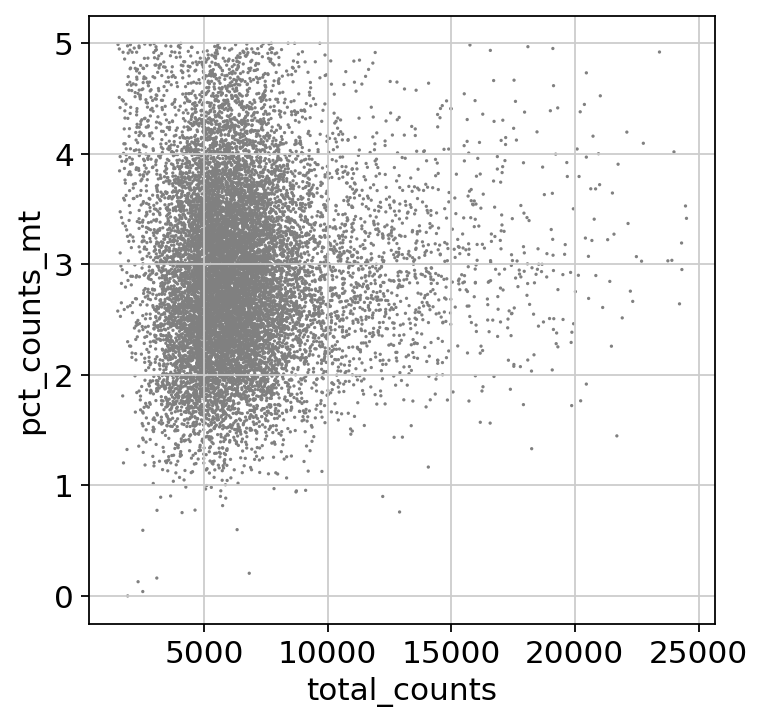

In [65]:
ad_gex.var['mt'] = ad_gex.var_names.str.startswith('MT-')  # annotate the group of mitochondrial genes as 'mt'
ad_gex.var['ribo'] = ad_gex.var_names.str.startswith(("RPS","RPL")) # ribosomal genes
ad_gex.var['hb'] = ad_gex.var_names.str.contains(("^HB[^(P)]")) # hemoglobin genes


ad_gex.var['tcr'] = ad_gex.var_names.str.contains(("TR[ABGD][VDJ]"))
sc.pp.calculate_qc_metrics(ad_gex, qc_vars=['mt','ribo','hb'], percent_top=None, log1p=False, inplace=True)
sc.pl.violin(ad_gex, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'],
             jitter=0.4, multi_panel=True)

initial_cells_n = ad_gex.shape[0]
print(f'Original cell n: {ad_gex.shape[0]}')

# mito content
ad_gex = ad_gex[ad_gex.obs.pct_counts_mt < 5, :]
print(f'MT filtering: {ad_gex.shape[0]} cells left')

# gene counts
ad_gex = ad_gex[(ad_gex.obs.total_counts > 1500)&(ad_gex.obs.total_counts < 25000), :]
ad_gex = ad_gex[(ad_gex.obs.n_genes_by_counts > 500)&(ad_gex.obs.n_genes_by_counts < 5000), :]
print(f'Counts filtering: {ad_gex.shape[0]} cells left')

ad_gex.layers['counts']=ad_gex.X.copy()
sc.pp.normalize_total(ad_gex, target_sum=1e4)
sc.pp.log1p(ad_gex)
sc.pp.highly_variable_genes(ad_gex, min_mean=0.05, max_mean=10, min_disp=0.3)
ad_gex.var['highly_variable'] = ad_gex.var['highly_variable']*~ad_gex.var['ribo']*~ad_gex.var['mt']*~ad_gex.var['tcr']
sc.pl.highly_variable_genes(ad_gex)
ad_gex.raw = ad_gex
# plot highly variable genes
ad_gex = ad_gex[:, ad_gex.var.highly_variable]
sc.pp.regress_out(ad_gex, ['total_counts', 'pct_counts_mt'])
sc.pp.scale(ad_gex, max_value=10)

# plot QC
sc.pl.violin(ad_gex, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'],
             jitter=0.4, multi_panel=True)

sc.pl.scatter(ad_gex, x='total_counts', y='pct_counts_mt')

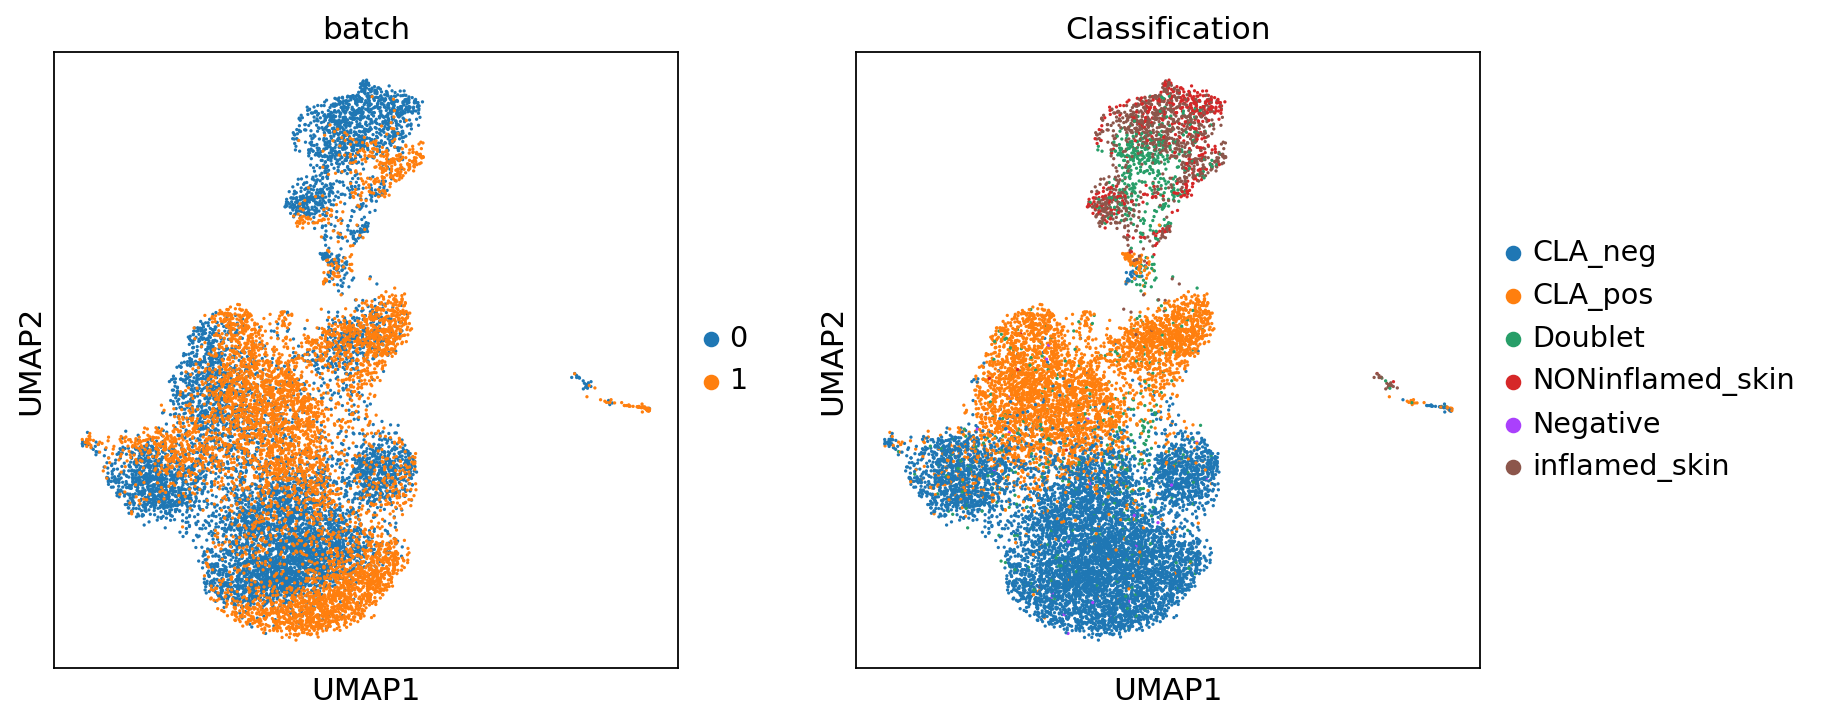

2026-11-02 13:22:18,351 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-11-02 13:22:20,394 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-11-02 13:22:20,453 - harmonypy - INFO - Iteration 1 of 10
2026-11-02 13:22:22,357 - harmonypy - INFO - Iteration 2 of 10
2026-11-02 13:22:24,304 - harmonypy - INFO - Iteration 3 of 10
2026-11-02 13:22:26,214 - harmonypy - INFO - Iteration 4 of 10
2026-11-02 13:22:28,237 - harmonypy - INFO - Iteration 5 of 10
2026-11-02 13:22:29,200 - harmonypy - INFO - Iteration 6 of 10
2026-11-02 13:22:29,876 - harmonypy - INFO - Iteration 7 of 10
2026-11-02 13:22:30,511 - harmonypy - INFO - Iteration 8 of 10
2026-11-02 13:22:31,216 - harmonypy - INFO - Iteration 9 of 10
2026-11-02 13:22:31,769 - harmonypy - INFO - Iteration 10 of 10
2026-11-02 13:22:32,324 - harmonypy - INFO - Converged after 10 iterations


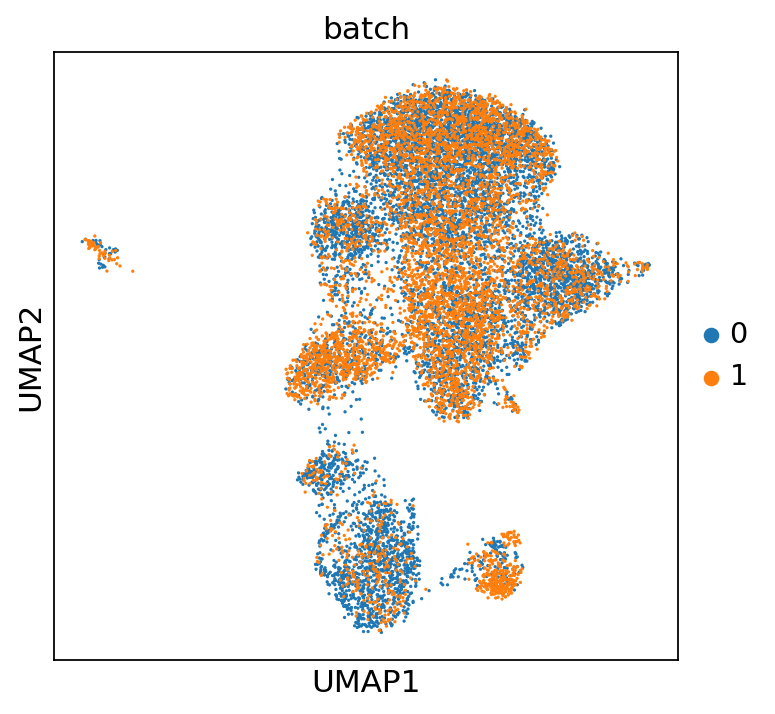

In [66]:
sc.tl.pca(ad_gex, svd_solver='arpack', n_comps=50)
sc.pp.neighbors(ad_gex)
sc.tl.umap(ad_gex)

sc.pl.umap(ad_gex, color=['batch', 'Classification'])
sc.external.pp.harmony_integrate(ad_gex, key='batch',)
sc.pp.neighbors(ad_gex, use_rep='X_pca_harmony')

sc.tl.umap(ad_gex)
sc.pl.umap(ad_gex, color=['batch'])

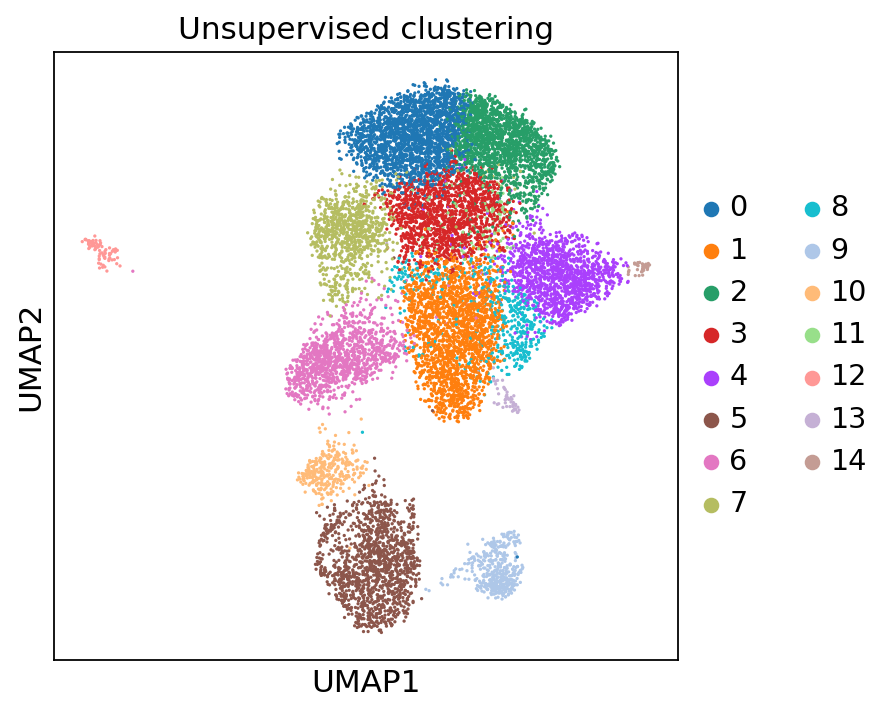

In [67]:
sc.tl.leiden(ad_gex, key_added='leiden', resolution=1)
sc.pl.umap(ad_gex, color='leiden', title='Unsupervised clustering')

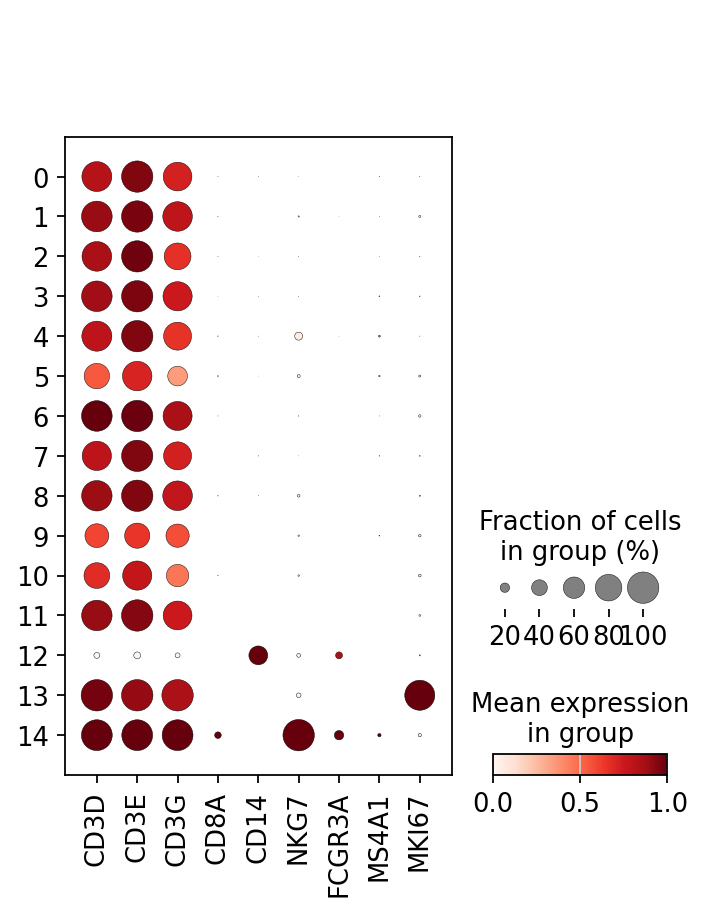

In [68]:
sc.pl.dotplot(ad_gex, groupby='leiden', var_names=['CD3D','CD3E','CD3G','CD8A','CD14','NKG7','FCGR3A','MS4A1','MKI67'], standard_scale='var')

In [69]:
ad_gex = ad_gex[~ad_gex.obs.leiden.isin(['12'])]
print(f'Removing non-CD4T cells: {ad_gex.shape[0]} cells left')

Removing non-CD4T cells: 13568 cells left


In [70]:
ad_gex=ad_gex[~ad_gex.obs.ambiguous]

In [71]:
ad_filtered = md.MuData({'gex':ad_gex, 'airr':ad['airr']})

In [72]:
ad_filtered.write("ad_filtered.h5mu")

## Clustering

In [73]:
ad = md.read('ad_filtered.h5mu')
ad = ad_loaded['gex']

2026-11-02 13:22:47,367 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-11-02 13:22:49,232 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-11-02 13:22:49,290 - harmonypy - INFO - Iteration 1 of 10
2026-11-02 13:22:50,978 - harmonypy - INFO - Iteration 2 of 10
2026-11-02 13:22:52,694 - harmonypy - INFO - Iteration 3 of 10
2026-11-02 13:22:54,418 - harmonypy - INFO - Iteration 4 of 10
2026-11-02 13:22:56,135 - harmonypy - INFO - Iteration 5 of 10
2026-11-02 13:22:56,894 - harmonypy - INFO - Iteration 6 of 10
2026-11-02 13:22:57,423 - harmonypy - INFO - Iteration 7 of 10
2026-11-02 13:22:57,986 - harmonypy - INFO - Iteration 8 of 10
2026-11-02 13:22:58,554 - harmonypy - INFO - Iteration 9 of 10
2026-11-02 13:22:59,117 - harmonypy - INFO - Iteration 10 of 10
2026-11-02 13:22:59,686 - harmonypy - INFO - Stopped before convergence


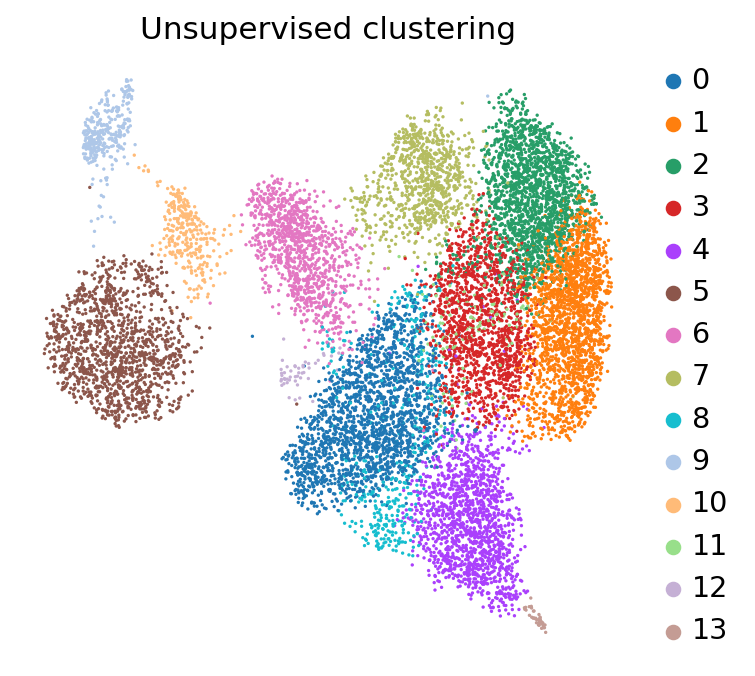

In [74]:
sc.tl.pca(ad_gex, svd_solver='arpack', n_comps=50)
sc.external.pp.harmony_integrate(ad_gex, key='batch',)
sc.pp.neighbors(ad_gex, use_rep='X_pca_harmony')
sc.tl.umap(ad_gex)
sc.tl.leiden(ad_gex, key_added='leiden', resolution=1.2)
sc.pl.umap(ad_gex, color='leiden', title='Unsupervised clustering', frameon=False)

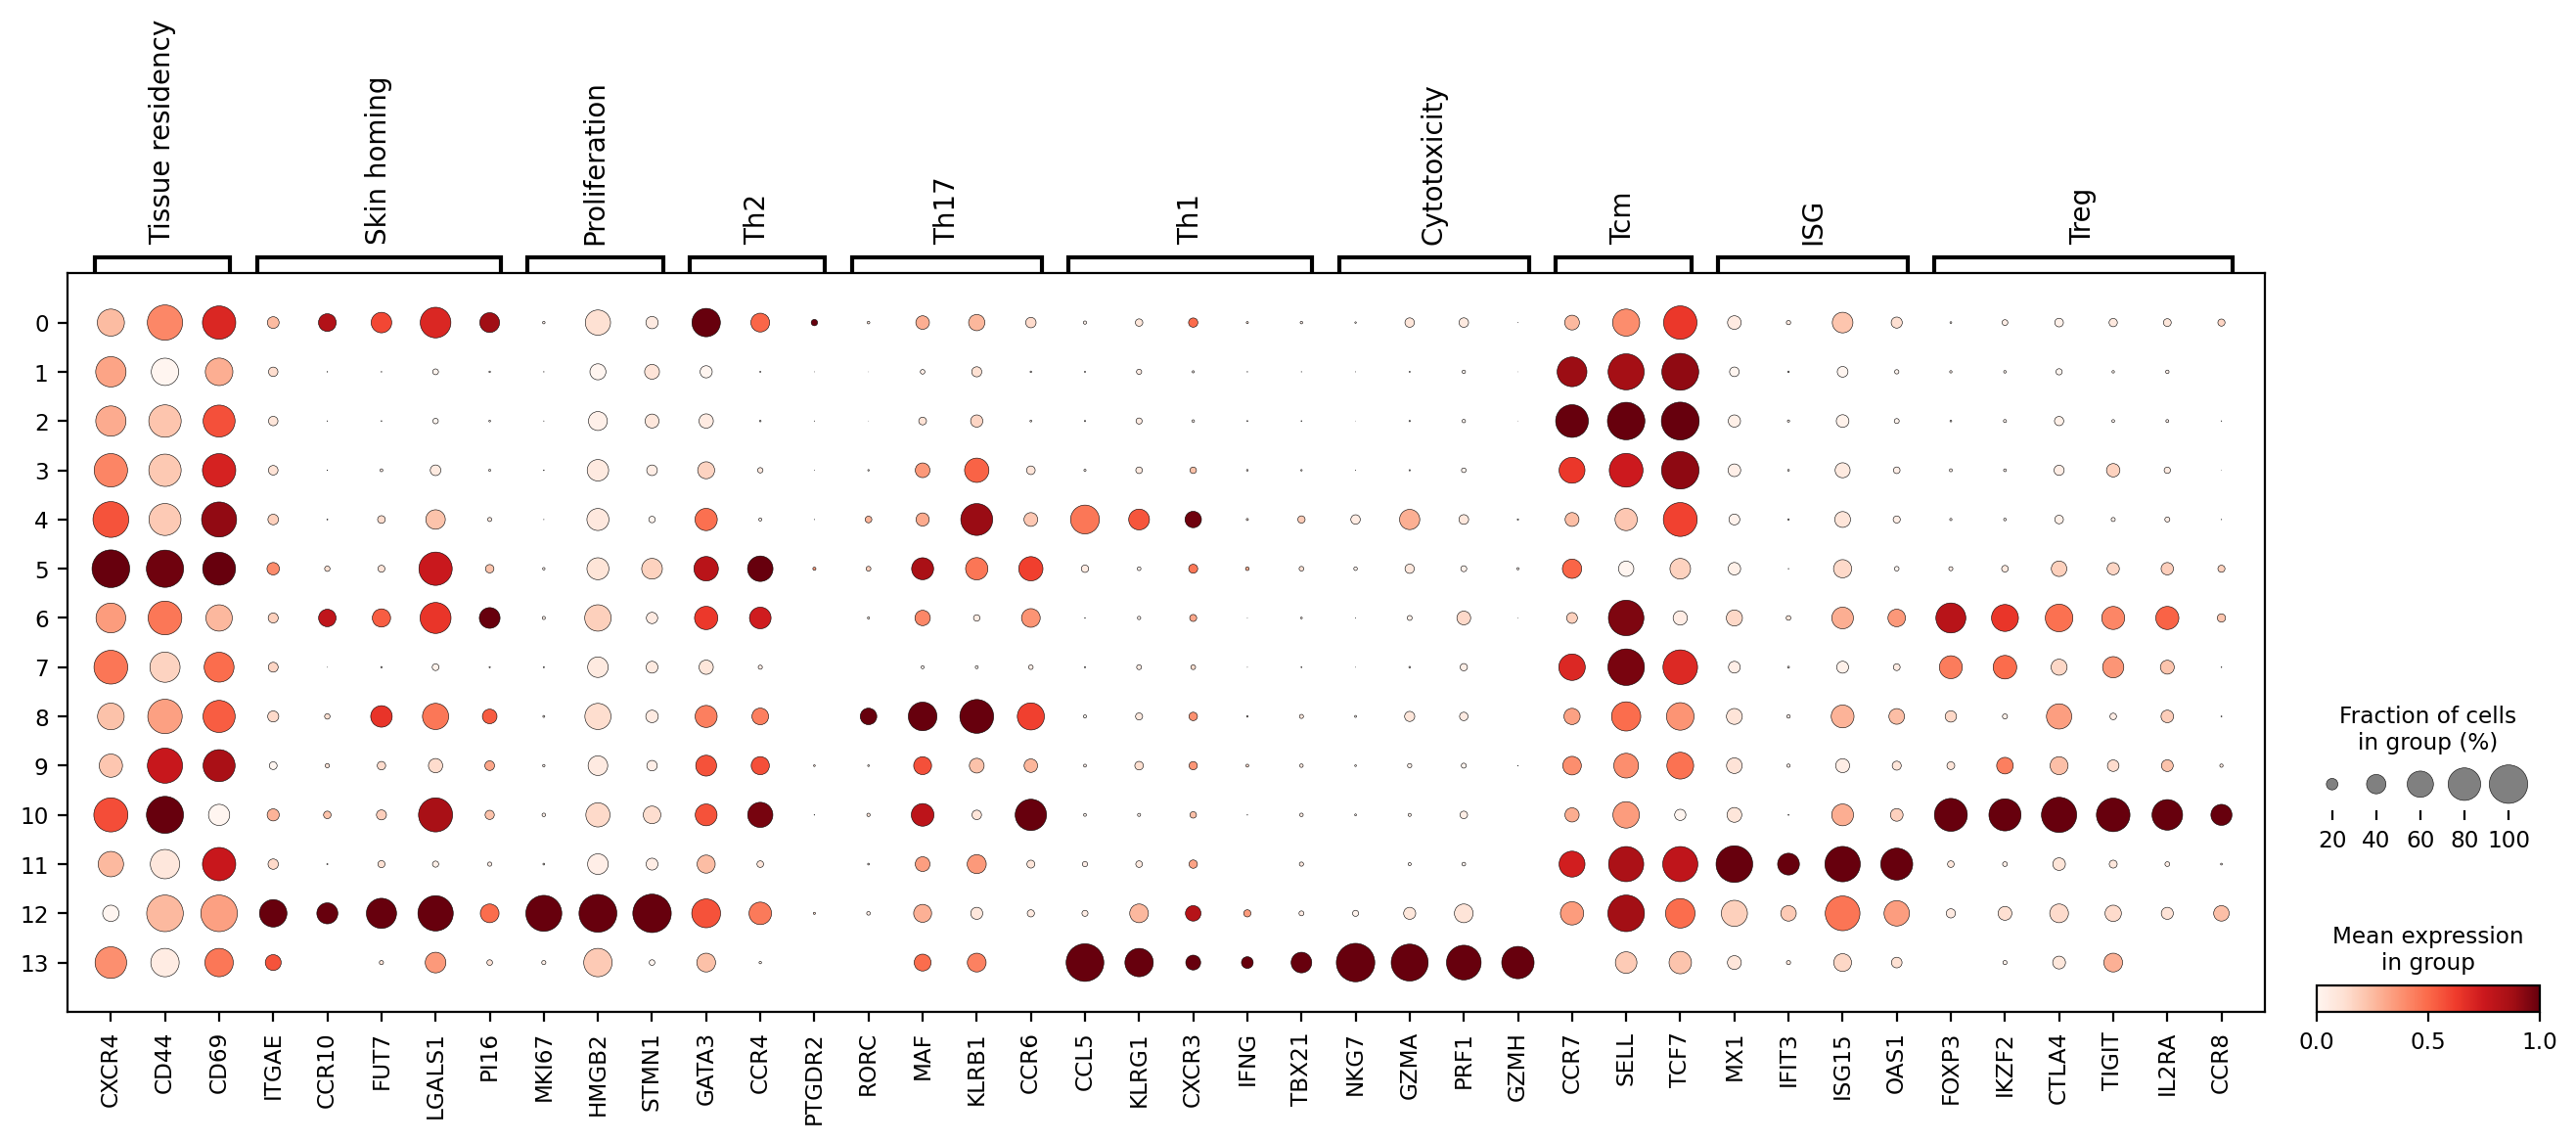

In [77]:
sns.reset_defaults()
gene_list = {
        
'Tissue residency':['CXCR4','CD44','CD69',],
    'Skin homing':['ITGAE','CCR10','FUT7','LGALS1','PI16'],
  'Proliferation':['MKI67','HMGB2','STMN1'],  
    'Th2':['GATA3','CCR4','PTGDR2'],
'Th17':['RORC','MAF','KLRB1','CCR6'],
'Th1':['CCL5','KLRG1','CXCR3','IFNG','TBX21'], 

'Cytotoxicity':['NKG7','GZMA','PRF1','GZMH'],
    'Tcm':['CCR7','SELL','TCF7'],

  'ISG':['MX1','IFIT3','ISG15','OAS1'],          
'Treg':['FOXP3','IKZF2','CTLA4','TIGIT','IL2RA','CCR8'],

}
sc.pl.dotplot(ad_gex, groupby='leiden',var_names=gene_list,
             standard_scale='var')

sc.set_figure_params(scanpy=True,
                     dpi=80,
                     dpi_save=200,
                     frameon=True,
                     vector_friendly=True,
                     fontsize=14,
                     figsize=(5,5),
                     color_map=None, 
                     format='pdf',
                     facecolor=None, transparent=False, ipython_format='png2x')

In [78]:
sc.tl.rank_genes_groups(ad_gex, groupby='leiden')
sc.get.rank_genes_groups_df(ad_gex, group='9')

,names,scores,logfoldchanges,pvals,pvals_adj
0,ARHGAP15,22.408731,2.145016,5.110086e-68,6.234475e-64
1,SMCHD1,20.263765,1.826611,6.905591e-60,6.318788e-56
2,PTPRC,20.110783,1.086759,2.131432e-59,1.560251e-55
3,MBNL1,20.075258,1.773211,5.670380e-59,3.459026e-55
4,SKAP1,19.137104,2.081230,3.051430e-55,8.987961e-52
...,...,...,...,...,...
36596,RPS3A,-19.416729,-2.508604,5.023032e-56,1.671345e-52
36597,EEF1B2,-19.445768,-2.181838,2.589814e-56,9.478977e-53
36598,RPL8,-19.625851,-2.438563,7.977383e-57,3.244224e-53
36599,RPS9,-20.026867,-2.256844,2.023449e-58,9.257530e-55


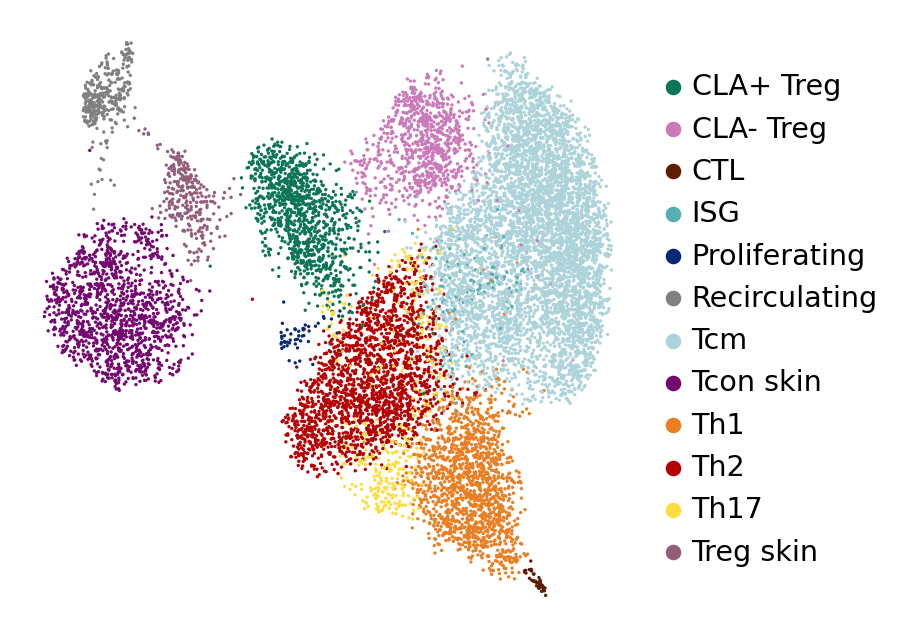

In [79]:
cluster_map = {
    '0':'Th2',
    '1':'Tcm',    
    '2':'Tcm',    
    '3':'Tcm',
    '4':'Th1',
    '5':'Tcon skin',
    '6':'CLA+ Treg',
    '7':'CLA- Treg',      
    '8':'Th17',
    '9':'Recirculating',
    '10':'Treg skin',    
    '11':'ISG',
    '12':'Proliferating',  
    '13':'CTL',

}

cluster_palette = {
    'Th1':'#EA7E23',
    'Th2':'#B50101',
    'Th17':'#FDDD40',
    'Tfh':'#ACD2DA',
    'Tcm':'#ACD2DA',
    'Early Tem':'#DC908A',
    'CLA- Treg':'#CA7AB9',
    'Tcon skin':'#750771',
    'Treg skin':'#925E7B',
    'CLA+ Treg':'#0C7557',
    'ISG':'#54AFB1',
    'Proliferating':'#052877',
    'CTL':'#5D1D02',
    'Recirculating':'grey'
}

cluster_order = ['Tcon skin',
                 'CLA+ Treg', 
                 'Recirculating',
                 'Proliferating',
                 'Th2',
                 'Th17',
                 'Th1', 
                 'CTL' ,
                 'Tcm',
                 'ISG',
                 'CLA- Treg', 
                'Treg skin',                
                  ]
ad_gex.obs['cluster'] = ad_gex.obs.leiden.map(cluster_map)
sc.pl.umap(ad_gex, color='cluster',palette=cluster_palette, frameon=False, title='')
ad_gex.obs['cluster'] = ad_gex.obs['cluster'].cat.reorder_categories(cluster_order)

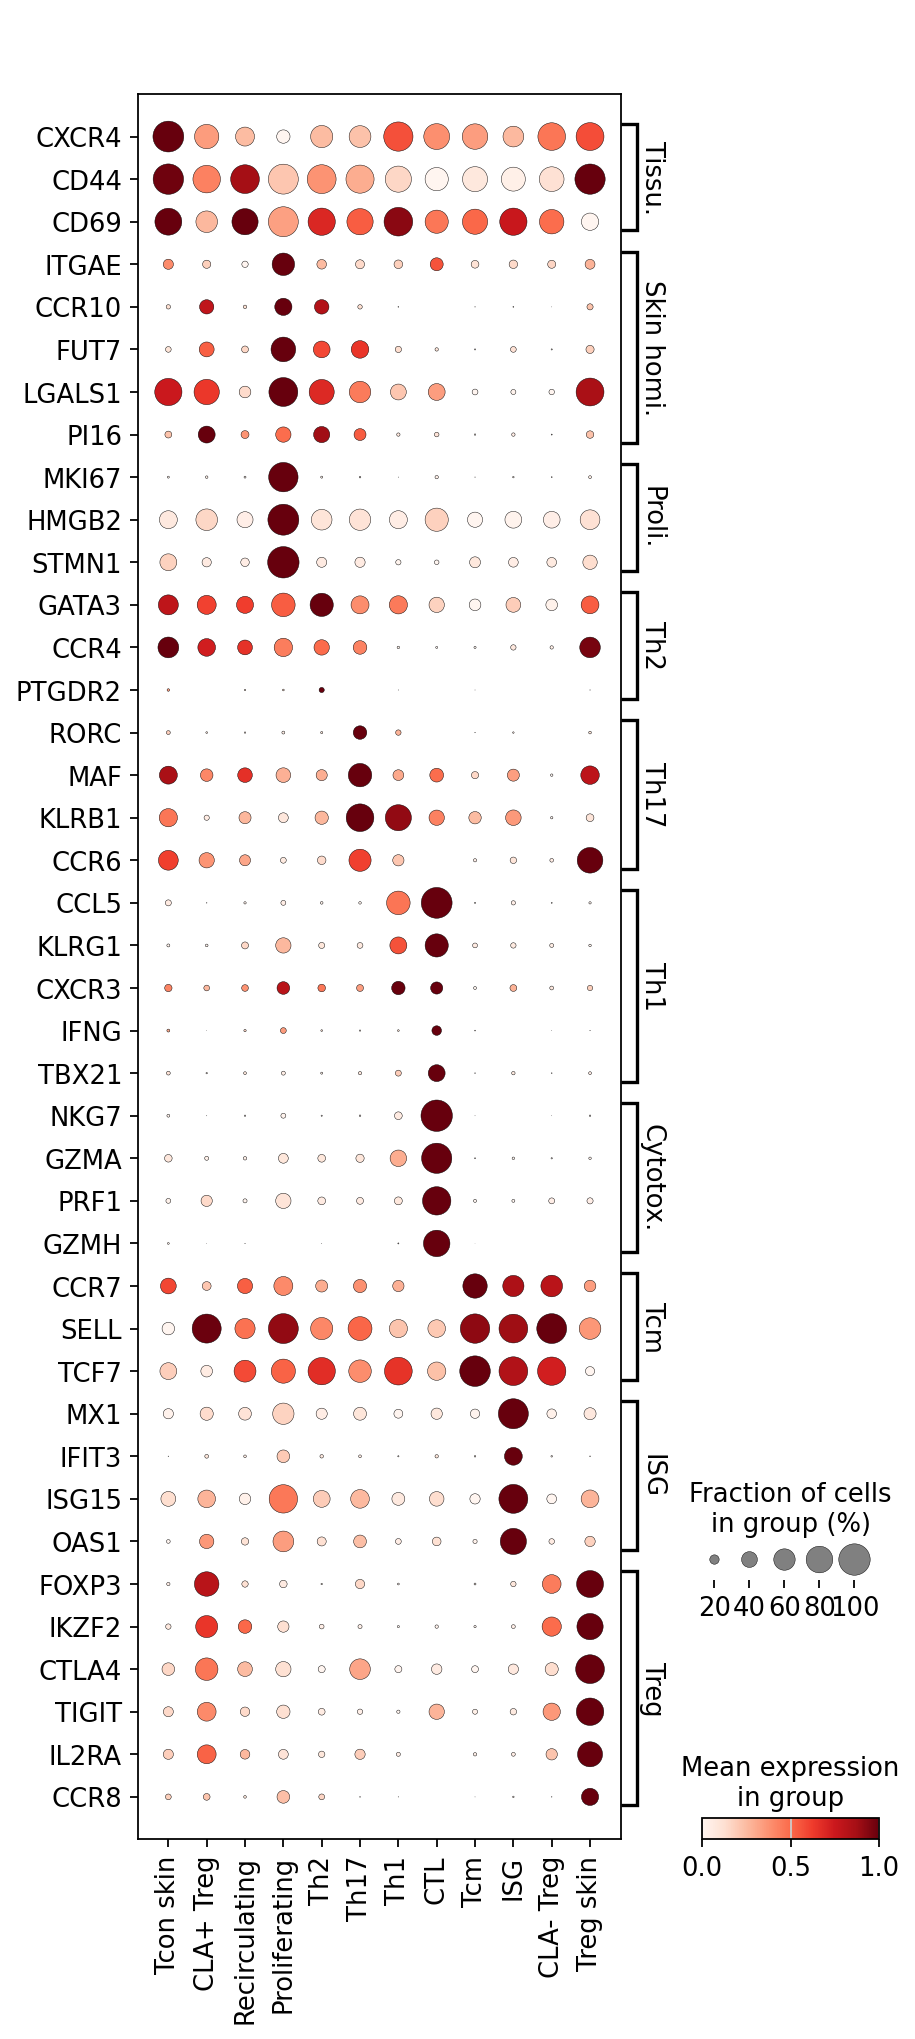

In [80]:
sc.pl.dotplot(ad_gex, groupby='cluster',var_names=gene_list,
             standard_scale='var', swap_axes=True)

sc.set_figure_params(scanpy=True,
                     dpi=80,
                     dpi_save=200,
                     frameon=True,
                     vector_friendly=True,
                     fontsize=14,
                     figsize=(5,5),
                     color_map=None, 
                     format='pdf',
                     facecolor=None, transparent=False, ipython_format='png2x')

## TCR analysis

In [81]:
ir.pp.index_chains(ad)
ir.tl.chain_qc(ad)
ir.pp.ir_dist(ad,metric='identity',sequence='aa')
ir.tl.define_clonotype_clusters(ad, sequence='aa',receptor_arms='VDJ',key_added='clone_id')

  0%|          | 0/11746 [00:00<?, ?it/s]

In [82]:
airr_cols = ir.get.airr(ad, ["junction_aa", "v_call"], ["VJ_1", "VDJ_1"])
ad_gex.obs[airr_cols.columns]=airr_cols

In [83]:
ad_gex.obs[['chain_pairing','clone_id','clone_id_size']] = ad['airr'].obs[['chain_pairing','clone_id','clone_id_size']]

In [84]:
ad_gex_tcr = ad_gex[ad_gex.obs.chain_pairing.isin(['single pair','orphan VDJ','extra VJ'])]

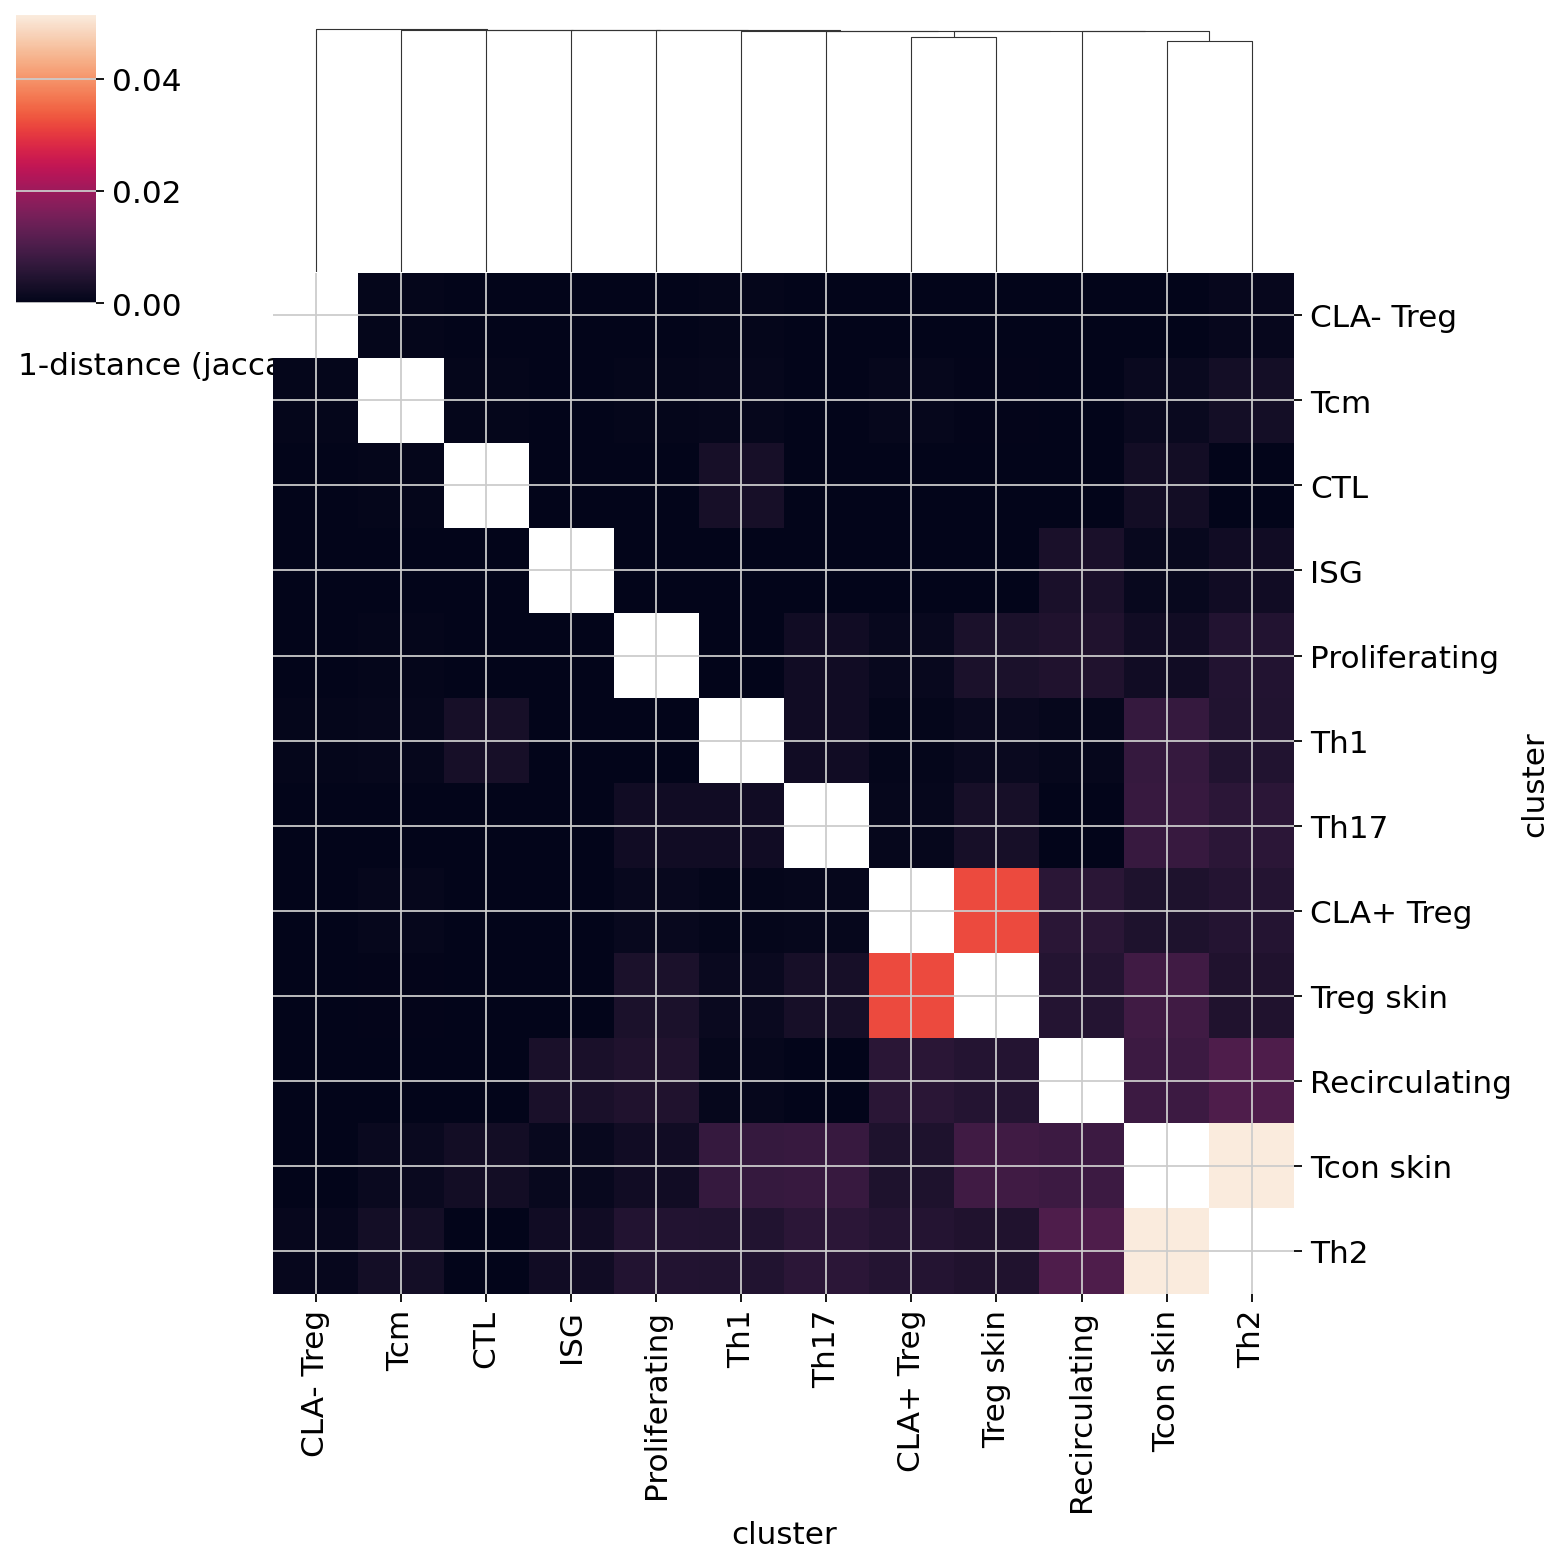

In [86]:
ir.pl.repertoire_overlap(ad_gex, groupby='cluster')
plt.show()

### Clone size

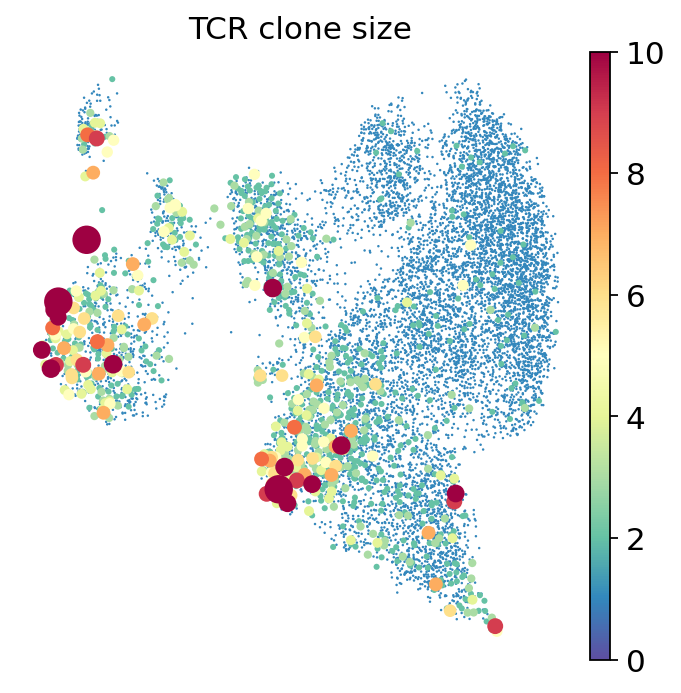

In [87]:
ad_gex_tcr.obs['group_col'] = ad_gex_tcr.obs['clone_id'].astype('str')+'_'+ad_gex_tcr.obs['cluster'].astype('str')
ad_gex_tcr.obs['clone_size_per_cluster'] = ad_gex_tcr.obs['group_col'].map(ad_gex_tcr.obs['group_col'].value_counts())
ad_gex_tcr_clonotypes = ad_gex_tcr[~ad_gex_tcr.obs.duplicated(['clone_id','cluster'])]

sc.pl.umap(ad_gex_tcr_clonotypes, color='clone_id_size',cmap='Spectral_r',vmax=10,vmin=0 ,
           size=5+25*(ad_gex_tcr_clonotypes.obs.clone_id_size-1),
           #save='_with_clone_sizes_rainbow.pdf',
           title='TCR clone size',
         #  add_outline=True,
   outline_color=('white','black'),outline_width=(0.01,0.01),
          frameon=False,)

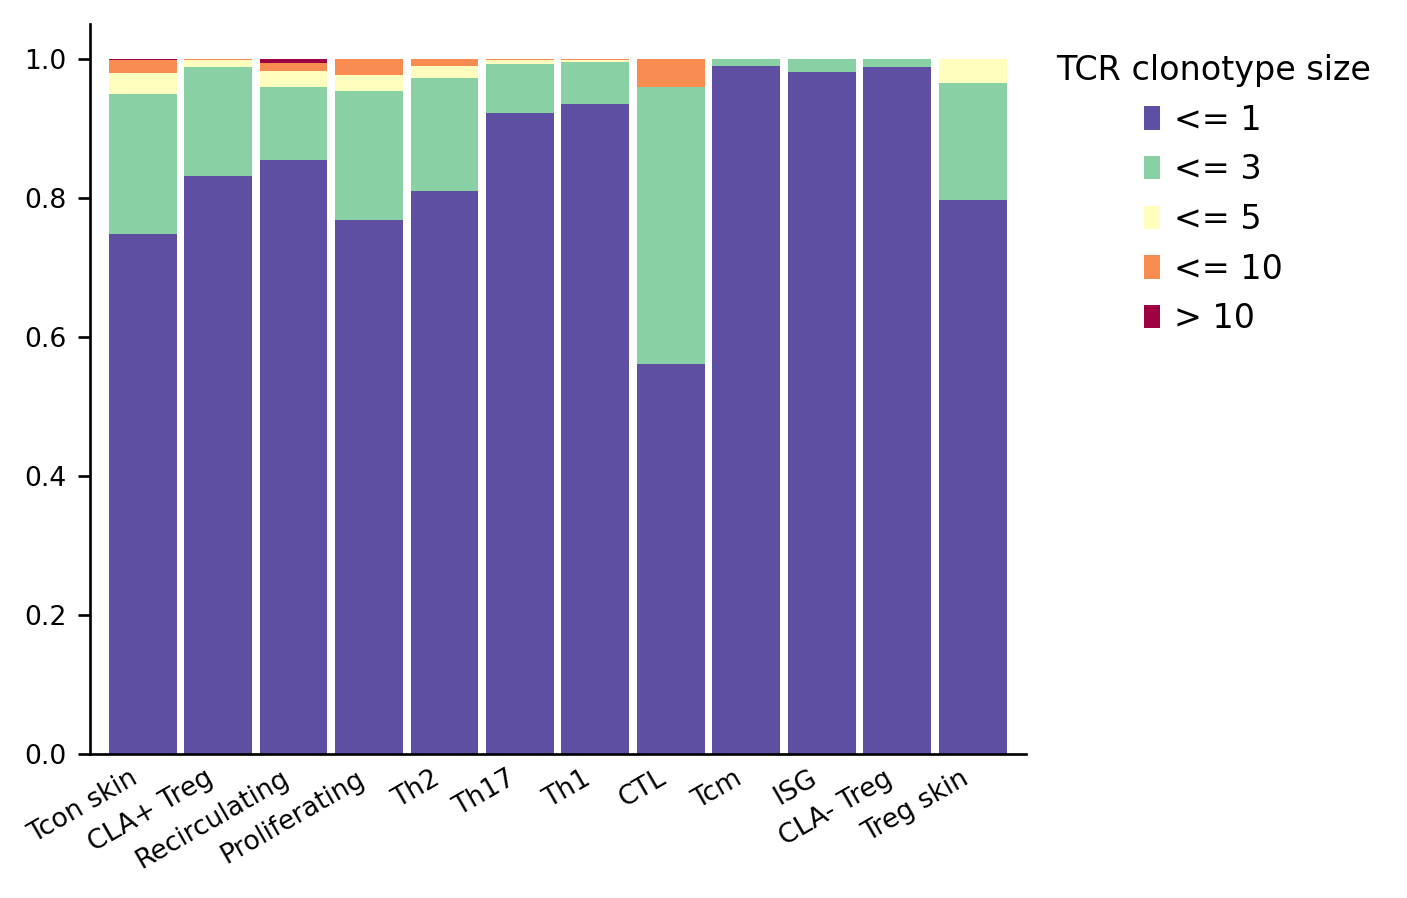

In [88]:
ax=ir.pl.clonal_expansion(ad_gex_tcr, groupby='cluster',
                          target_col='clone_id',
                       summarize_by='clone_id',
                       linewidth=0,
                       width=0.9,
                       colormap='Spectral_r',
                       figsize=(5,4),
                       breakpoints=(1, 3, 5, 10)
                      )
h, l = ax.get_legend_handles_labels()
ax.legend(handles=h, labels=l, title="TCR clonotype size",
          fontsize=10,
      title_fontsize=10,
        loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
#ax.set_xticklabels(['HC','HC \nC.albicans-specific','irAE','irAE \nC.albicans-specific'],fontdict={'fontsize': 10,
#        'horizontalalignment': 'center'},
#                   rotation=0)
plt.show()

### TCR overlap between samples

In [89]:
def morisitaHorn(data1, data2):
    X = sum(data1)
    Y = sum(data2)

    if len(data1) != len(data2):
        raise ValueError("Error while calculating MorisitaHorn similarity index. The two input data lists must have the same length!\n")
    
    if X == 0 or Y == 0:
        return -1

    sumXiYi = 0
    sumXiSqr = 0
    sumYiSqr = 0

    for i, x in enumerate(data1):
        y = data2[i]
        sumXiYi += x*y
        sumXiSqr += x*x
        sumYiSqr += y*y

    numerator = 2*sumXiYi
    denominator = ( float(sumXiSqr)/(X*X) + float(sumYiSqr)/(Y*Y) )*X*Y

    return float(numerator)/denominator


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/usr/lib/python3.10/runpy.py", line 196, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/usr/lib/python3.10/runpy.py", line 86, in _run_code
    exec(code, run_globals)
  File "/home/user/Projects/tcr_venv/lib/python3.10/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/home/user/Projects/tcr_venv/lib/python3.10/site-packages/traitlets/config/application.py", line 1043, in launch_instance
    app.start()
  File "/home/user/Projects/tcr_v

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/usr/lib/python3.10/runpy.py", line 196, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/usr/lib/python3.10/runpy.py", line 86, in _run_code
    exec(code, run_globals)
  File "/home/user/Projects/tcr_venv/lib/python3.10/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/home/user/Projects/tcr_venv/lib/python3.10/site-packages/traitlets/config/application.py", line 1043, in launch_instance
    app.start()
  File "/home/user/Projects/tcr_v

AttributeError: _ARRAY_API not found

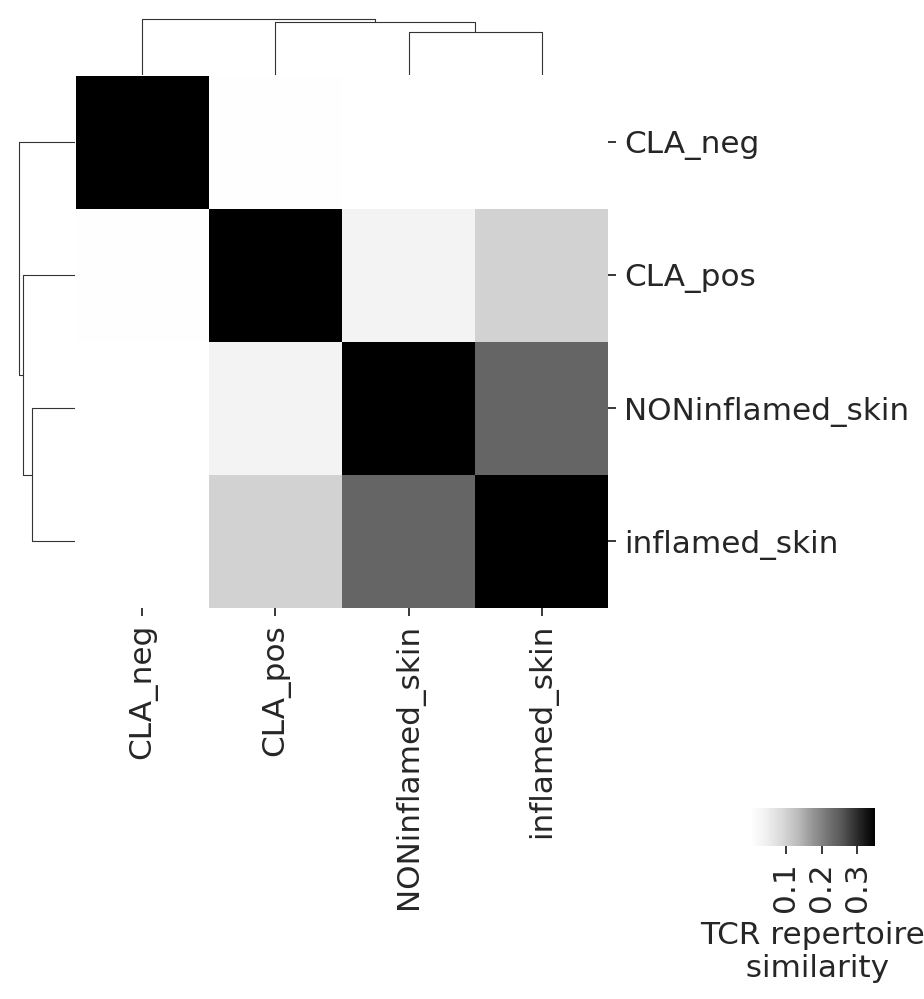

In [90]:
sns.set_style('ticks')

ad_gex.obs['dummy'] = 1
tcr_cluster_distance = {}
df = ad_gex.obs.groupby(['hash','VDJ_1_junction_aa']).dummy.sum().reset_index()

for i in ad_gex.obs['hash'].unique():
    tcr_cluster_distance[i] = {}
    for j in ad_gex.obs['hash'].unique():
         tcr_cluster_distance[i][j] = morisitaHorn(df[df['hash']==i].set_index('VDJ_1_junction_aa').dummy, df[df['hash']==j].set_index('VDJ_1_junction_aa').dummy,) 



ax = sns.clustermap(pd.DataFrame(tcr_cluster_distance), vmax=0.35,cmap='Greys',dendrogram_ratio=0.1,cbar_pos=(0.8, 0.1, 0.13, 0.04),
                   # col_colors=pd.Series(ad_gex_cluster_pal),
              # row_colors=pd.Series(ad_gex_cluster_pal),
                  #  row_cluster=False,
                   # col_cluster=False,
                    cbar_kws={'label':'TCR repertoire\n similarity',
                                                                                'location':'bottom',
                                                                              # 'orientation':'vertical'
                                                                               },figsize=(6,6))
# Move row labels (yticks) to the left
#ax.ax_heatmap.yaxis.tick_left()
#ax.ax_heatmap.yaxis.set_label_position('left')

# Optional: remove right-side ticks to avoid double labels
#ax.ax_heatmap.tick_params(axis='y', which='both', right=False)
ax.tick_params('x', rotation=90)
ax.tick_params('y', rotation=0)
plt.tight_layout()
plt.show()
#plt.savefig('heatmap_TCR_overlap.pdf')

In [91]:
common_tcr_blood_skin = set(ad_gex.obs[(ad_gex.obs.hash.str.contains('skin'))&(ad_gex.obs.clone_id_size>1)]['VDJ_1_junction_aa'].dropna().values)&set(ad_gex.obs[ad_gex.obs.hash.str.contains('CLA')]['VDJ_1_junction_aa'].values)
common_tcr_blood_infl_skin = set(ad_gex.obs[(ad_gex.obs.hash=='inflamed_skin')&(ad_gex.obs.clone_id_size>1)]['VDJ_1_junction_aa'].dropna().values)&set(ad_gex.obs[ad_gex.obs.hash.str.contains('CLA')]['VDJ_1_junction_aa'].values)
common_tcr_blood_noninfl_skin = set(ad_gex.obs[(ad_gex.obs.hash=='NONinflamed_skin')&(ad_gex.obs.clone_id_size>1)]['VDJ_1_junction_aa'].dropna().values)&set(ad_gex.obs[ad_gex.obs.hash.str.contains('CLA')]['VDJ_1_junction_aa'].values)

In [92]:
pbmc = ad_gex[ad_gex.obs.hash.str.contains('CLA')]
skin = ad_gex[ad_gex.obs.hash.str.contains('skin')]

In [93]:
umap_coords = pd.DataFrame(data=ad_gex.obsm['X_umap'], index=ad_gex.obs.index, columns=['UMAP1','UMAP2'])

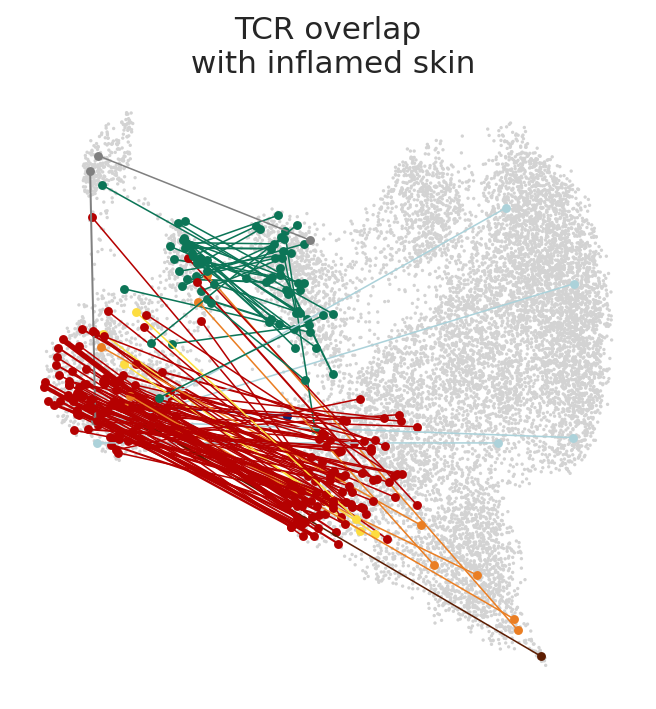

In [94]:
sc.pl.umap(ad_gex,show=False, frameon=False, title='TCR overlap\n with inflamed skin')
for tcr in list(common_tcr_blood_infl_skin):
    subset = ad_gex.obs[ad_gex.obs.VDJ_1_junction_aa==tcr]
    # find cluster in blood to get the color,  select 1st cell from blood (cluster matching)
    pbmc_sub = pbmc.obs[pbmc.obs.VDJ_1_junction_aa==tcr]
    cluster=pbmc_sub['cluster'].mode().values[0]
    pbmc_cell = pbmc_sub[pbmc_sub.cluster==cluster].index[0]
    coo_pbmc = umap_coords.loc[pbmc_cell].values
    # select 1st cell from skin
    skin_sub = skin.obs[skin.obs.VDJ_1_junction_aa==tcr]
    skin_cell = skin_sub.index[0]
    coo_skin = umap_coords.loc[skin_cell].values
    plt.plot([coo_pbmc[0],coo_skin[0]],
             [coo_pbmc[1],coo_skin[1]],
             marker='.',
             lw=0.5+0.2*subset[subset.hash=='inflamed_skin'].shape[0],
             mfc=cluster_palette[cluster],
             color=cluster_palette[cluster],
        )
plt.show()

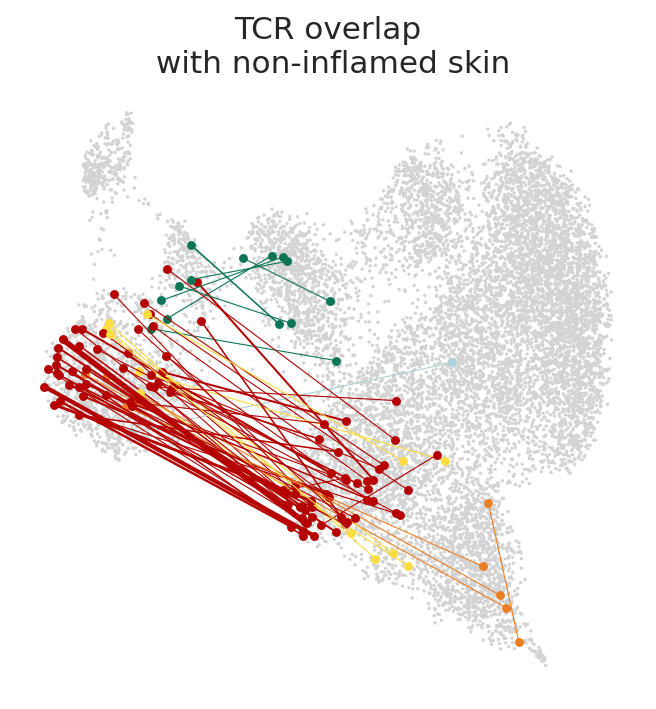

In [95]:
sc.pl.umap(ad_gex,show=False, frameon=False, title='TCR overlap\n with non-inflamed skin')
for tcr in list(common_tcr_blood_noninfl_skin):
    subset = ad_gex.obs[ad_gex.obs.VDJ_1_junction_aa==tcr]
    # find cluster in blood to get the color,  select 1st cell from blood (cluster matching)
    pbmc_sub = pbmc.obs[pbmc.obs.VDJ_1_junction_aa==tcr]
    cluster=pbmc_sub['cluster'].mode().values[0]
    pbmc_cell = pbmc_sub[pbmc_sub.cluster==cluster].index[0]
    coo_pbmc = umap_coords.loc[pbmc_cell].values
    # select 1st cell from skin
    skin_sub = skin.obs[skin.obs.VDJ_1_junction_aa==tcr]
    skin_cell = skin_sub.index[0]
    coo_skin = umap_coords.loc[skin_cell].values
    plt.plot([coo_pbmc[0],coo_skin[0]],
             [coo_pbmc[1],coo_skin[1]],
             marker='.',
             lw=0.5+0.2*subset[subset.hash=='inflamed_skin'].shape[0],
             mfc=cluster_palette[cluster],
             color=cluster_palette[cluster],
        )
plt.show()

In [108]:
cl_cluster_map = pbmc[pbmc.obs.VDJ_1_junction_aa.isin(common_tcr_blood_skin)].obs.groupby('VDJ_1_junction_aa')['cluster'].first().astype('str')
skin.obs['TCR_cluster_in_pbmc'] = skin.obs['VDJ_1_junction_aa'].map(cl_cluster_map).fillna('not_in_blood')

In [97]:
cluster_order

['Tcon skin',
 'CLA+ Treg',
 'Recirculating',
 'Proliferating',
 'Th2',
 'Th17',
 'Th1',
 'CTL',
 'Tcm',
 'ISG',
 'CLA- Treg',
 'Treg skin']

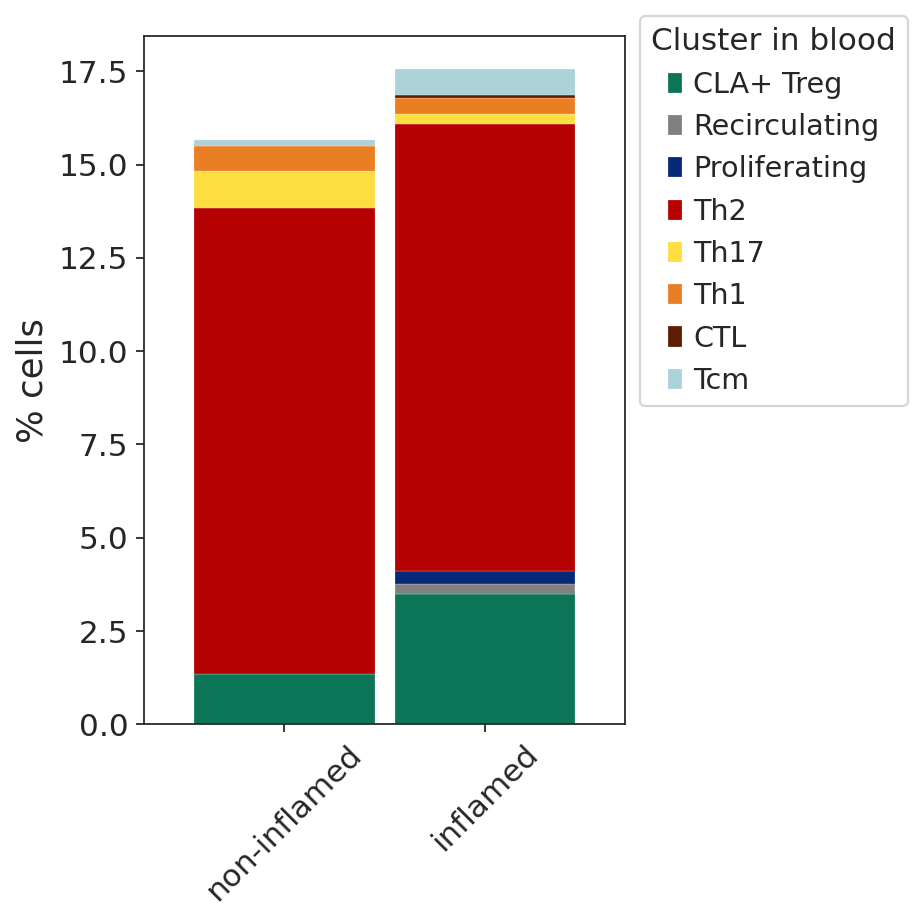

In [102]:

fig,ax=plt.subplots(1,1, figsize=(6,6))
pd.pivot_table(skin.obs, columns='TCR_cluster_in_pbmc', index='hash',  aggfunc='count',values='batch').apply(lambda x: 100*x/x.sum(), axis=1)[[
 'CLA+ Treg',
 'Recirculating',
 'Proliferating',
 'Th2',
 'Th17',
 'Th1',
 'CTL',
 'Tcm']].plot(kind='bar',
    stacked=True, linewidth=0.1,
            ax=ax,
    width=0.9,
    color=cluster_palette )
ax.legend(bbox_to_anchor=(1, 1.05), title='Cluster in blood',title_fontsize=14)
ax.set_xlabel('')
ax.set_ylabel('% cells',fontsize=16)
ax.set_xticklabels(['non-inflamed','inflamed'], rotation=45)
plt.tight_layout()
plt.show()

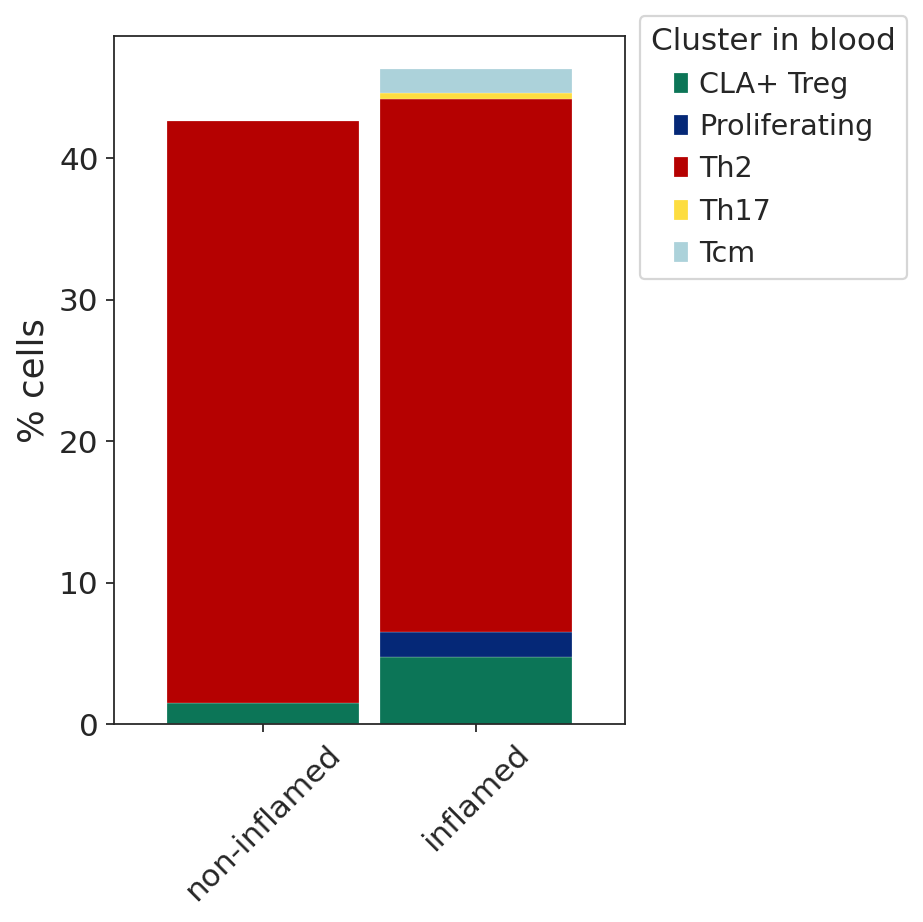

In [104]:
skin.obs['clone_size_in_skin'] = skin.obs['clone_id'].map(skin.obs['clone_id'].value_counts())
skin_expanded = skin[skin.obs.clone_size_in_skin>1].copy()
fig,ax=plt.subplots(1,1, figsize=(6,6))
pd.pivot_table(skin_expanded.obs, columns='TCR_cluster_in_pbmc', index='hash',  aggfunc='count',values='batch').apply(lambda x: 100*x/x.sum(), axis=1)[[
 'CLA+ Treg',
 #'Recirculating',
 'Proliferating',
 'Th2',
 'Th17',
# 'Th1',
 #'CTL',
 'Tcm',
# 'CLA- Treg'
]].plot(kind='bar',
    stacked=True, linewidth=0.1,
            ax=ax,
    width=0.9,
    color=cluster_palette)
ax.legend(bbox_to_anchor=(1, 1.05), title='Cluster in blood',title_fontsize=14)
ax.set_xlabel('')
ax.set_ylabel('% cells',fontsize=16)
ax.set_xticklabels(['non-inflamed','inflamed'], rotation=45)
plt.tight_layout()
plt.show()

### downsampling

In [118]:
ad_gex.obs['donor']=ad_gex.obs.batch.map({'0':'D1','1':'D2'})
ad_gex.obs['tissue']=ad_gex.obs['hash'].apply(lambda x: 'skin' if 'skin' in x else 'PBMC')

In [120]:
pbmc = ad_gex[ad_gex.obs.tissue=='PBMC']
skin = ad_gex[ad_gex.obs.tissue=='skin']

In [218]:
# downsample to 300
rng = np.random.default_rng(42)
n_target = 300 
n_rep = 100 

res_infl = []
res_infl_expanded = []
res_noninfl = []
res_noninfl_expanded = []

for _ in range(n_rep):
    downsampled = []
    for (donor, tissue), g in ad_gex.obs.groupby(["donor", 'hash'], observed=True):
        subset = g[['clone_id','cluster','tissue','hash']]
        if len(g) < n_target:
            subset_downsampled = subset    
        else:
            idx = rng.choice(len(subset), size=n_target, replace=False)
            subset_downsampled = subset.iloc[idx]
        downsampled.append(subset_downsampled)
    downsampled = pd.concat(downsampled)
    downsampled_pbmc = downsampled[downsampled.tissue=='PBMC']
    downsampled_skin = downsampled[downsampled.tissue=='skin']
    overlapping_clones = set(downsampled_pbmc['clone_id'].dropna().values)&set(downsampled_skin['clone_id'].dropna().values)
    downsampled_pbmc['cluster'] = downsampled_pbmc['cluster'].astype('str')
    cl_cluster_map = downsampled_pbmc[downsampled_pbmc.clone_id.isin(overlapping_clones)].groupby('clone_id')['cluster'].first()
    downsampled_skin['TCR_cluster_in_pbmc'] = downsampled_skin['clone_id'].map(cl_cluster_map).fillna('not_in_blood')
    
    downsampled_skin_infl = downsampled_skin[downsampled_skin['hash']=='inflamed_skin']
    percent_overlap_infl = (downsampled_skin_infl['TCR_cluster_in_pbmc'].value_counts()/downsampled_skin_infl.shape[0]).to_frame().T
    res_infl.append(percent_overlap_infl)
    
    downsampled_skin_noninfl = downsampled_skin[downsampled_skin['hash']=='NONinflamed_skin']
    percent_overlap_noninfl = (downsampled_skin_noninfl['TCR_cluster_in_pbmc'].value_counts()/downsampled_skin_noninfl.shape[0]).to_frame().T
    res_noninfl.append(percent_overlap_noninfl)
    
    downsampled_skin['clone_id_size'] = downsampled_skin['clone_id'].map(downsampled_skin['clone_id'].value_counts())
    downsampled_skin_expanded = downsampled_skin[downsampled_skin['clone_id_size']>1]
    overlapping_clones = set(downsampled_pbmc['clone_id'].dropna().values)&set(downsampled_skin_expanded['clone_id'].dropna().values)
    cl_cluster_map = downsampled_pbmc[downsampled_pbmc.clone_id.isin(overlapping_clones)].groupby('clone_id')['cluster'].first()
    
    downsampled_skin_expanded['TCR_cluster_in_pbmc'] = downsampled_skin_expanded['clone_id'].map(cl_cluster_map).fillna('not_in_blood')
    
    downsampled_skin_infl_expanded = downsampled_skin_expanded[downsampled_skin_expanded['hash']=='inflamed_skin']
    percent_overlap_infl_expanded = (downsampled_skin_infl_expanded['TCR_cluster_in_pbmc'].value_counts()/downsampled_skin_infl_expanded.shape[0]).to_frame().T
    res_infl_expanded.append(percent_overlap_infl_expanded)
    
    downsampled_skin_noninfl_expanded = downsampled_skin_expanded[downsampled_skin_expanded['hash']=='NONinflamed_skin']
    percent_overlap_noninfl_expanded = (downsampled_skin_noninfl_expanded['TCR_cluster_in_pbmc'].value_counts()/downsampled_skin_noninfl_expanded.shape[0]).to_frame().T
    res_noninfl_expanded.append(percent_overlap_noninfl_expanded)


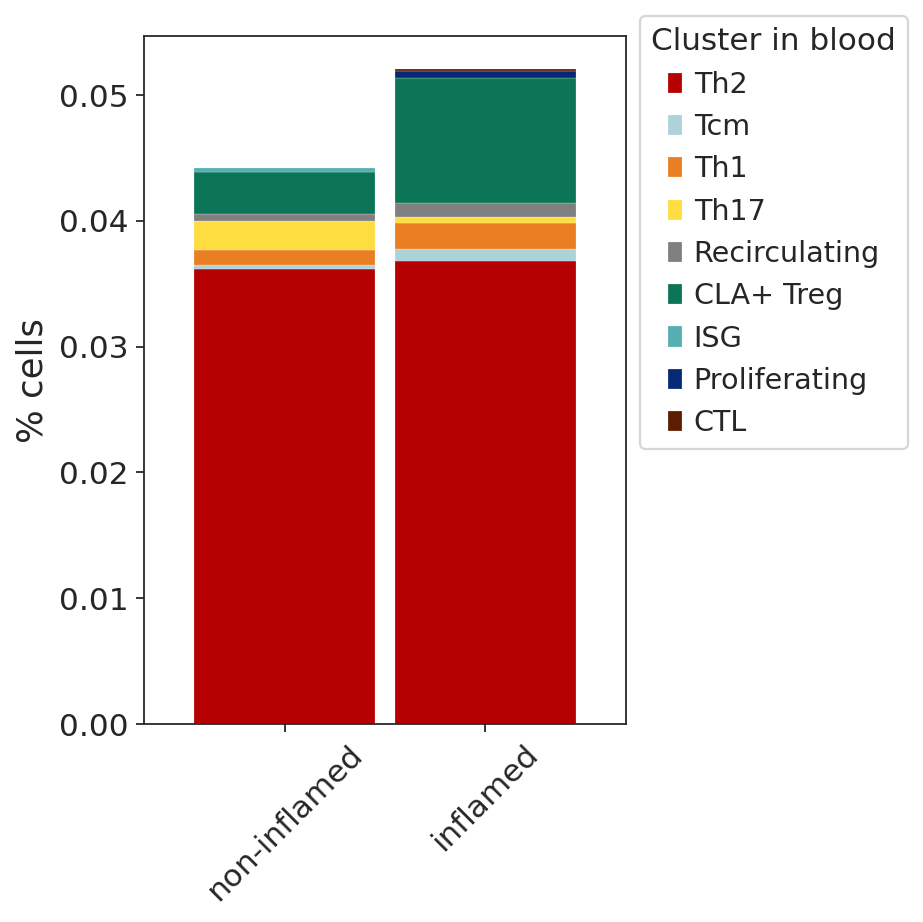

In [237]:
conc_res = pd.concat([pd.concat(res_noninfl).fillna(0).apply('mean'),
                      pd.concat(res_infl).fillna(0).apply('mean')],
                    axis=1)
conc_res.columns = [ 'non-inflamed','inflamed']

fig,ax=plt.subplots(1,1, figsize=(6,6))
conc_res.drop('not_in_blood').T.plot(kind='bar',
    stacked=True, linewidth=0.1,
            ax=ax,
    width=0.9,
    color=cluster_palette )
ax.legend(bbox_to_anchor=(1, 1.05), title='Cluster in blood',title_fontsize=14)
ax.set_xlabel('')
ax.set_ylabel('% cells',fontsize=16)
ax.set_xticklabels(['non-inflamed','inflamed'], rotation=45)
plt.tight_layout()
plt.show()

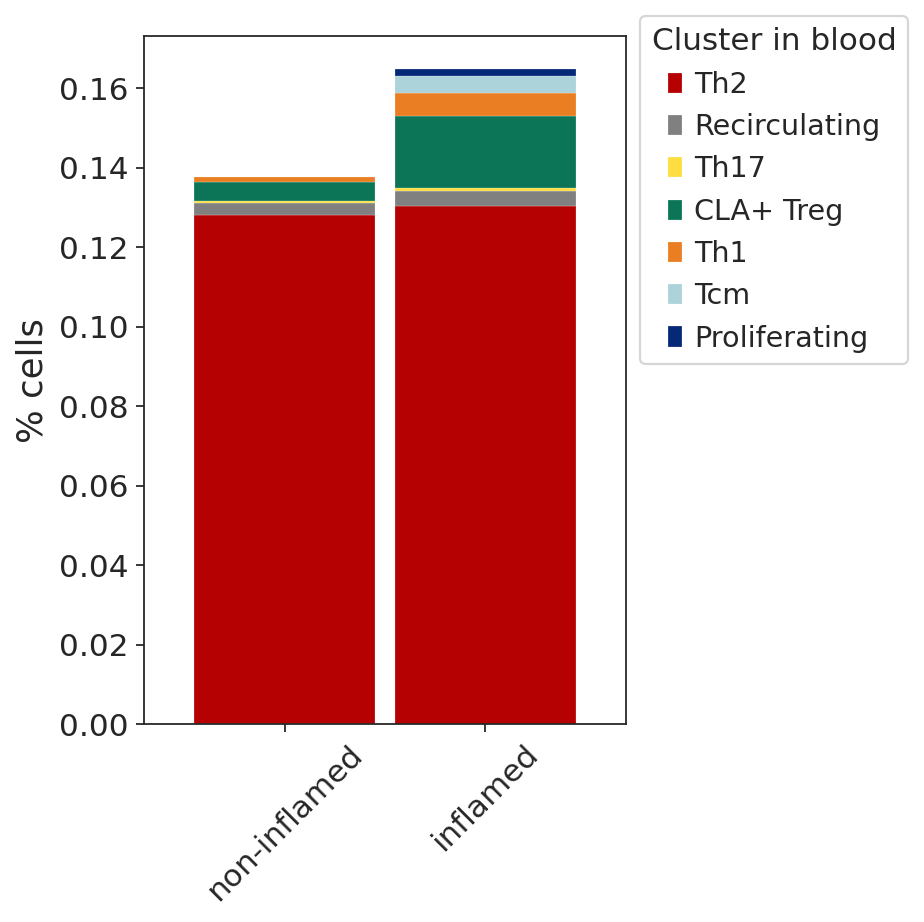

In [238]:
conc_res_expanded = pd.concat([pd.concat(res_noninfl_expanded).fillna(0).apply('mean'),
                      pd.concat(res_infl_expanded).fillna(0).apply('mean')],
                    axis=1)
conc_res.columns = ['non-inflamed','inflamed']

fig,ax=plt.subplots(1,1, figsize=(6,6))
conc_res_expanded.drop('not_in_blood').T.plot(kind='bar',
    stacked=True, linewidth=0.1,
            ax=ax,
    width=0.9,
    color=cluster_palette )
ax.legend(bbox_to_anchor=(1, 1.05), title='Cluster in blood',title_fontsize=14)
ax.set_xlabel('')
ax.set_ylabel('% cells',fontsize=16)
ax.set_xticklabels(['non-inflamed','inflamed'], rotation=45)
plt.tight_layout()
plt.show()